# Homework 6
**Name:** Hao Pang **ID:** 6495868529 **Course:** DSCI 552

## 1. Tree-Based Methods
### (a) Load the APS Failure Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42

def load_aps(path):
    with open(path) as f:
        for skiprows, line in enumerate(f):
            if line.startswith("class,"):
                break
    return pd.read_csv(path, skiprows=skiprows, na_values="na")

train = load_aps("aps_failure_training_set.csv")
test = load_aps("aps_failure_test_set.csv")

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (60000, 171)
Test set: (16000, 171)


### (b) Data Preparation
#### (i) Missing Values

In [2]:
X_train, X_test = train.drop(columns="class"), test.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})

pd.DataFrame({
    "Missing values": [X.isna().sum().sum() for X in (X_train, X_test)],
    "Features with missing values": [X.isna().any().sum() for X in (X_train, X_test)],
    "Rows with missing values": [X.isna().any(axis=1).sum() for X in (X_train, X_test)]
}, index=["Training", "Test"])

,Missing values,Features with missing values,Rows with missing values
Training,850015,169,59409
Test,228680,169,15835


Common imputation methods include row deletion, mean/median imputation, KNN imputation, iterative (model-based) imputation, and adding missing-value indicators. Dropping incomplete rows would remove about 99% of the training data, so I used **median imputation**, which is simple and robust to the extreme values in this data. Following the homework's footnote, each set is imputed with its own column medians.

Reference: [Scikit-learn: Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html)

In [3]:
X_train_imp = X_train.fillna(X_train.median())
X_test_imp = X_test.fillna(X_test.median())   # test set uses its own medians (footnote 1)
print("Remaining missing values:", X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

Remaining missing values: 0 0


#### (ii) Coefficient of Variation

I calculated the coefficient of variation for each feature using the
imputed training data. CV is the sample standard deviation divided by
the mean. The table below shows the 13 features with the highest CV.

In [4]:
cv_table = pd.DataFrame({"Mean": X_train_imp.mean(), "Sample SD": X_train_imp.std(ddof=1)})
cv_table["CV"] = cv_table["Sample SD"] / cv_table["Mean"].replace(0, np.nan)
cv_table = cv_table.sort_values("CV", ascending=False)
cv_table.head(13).round(4)

,Mean,Sample SD,CV
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337
ak_000,907.6607,7.299859e+04,80.4250


#### (iii) Correlation Matrix

cd_000 is constant in the training set, so its correlations are undefined; it is excluded from the heatmap only (169 features shown).

Constant features excluded: ['cd_000']


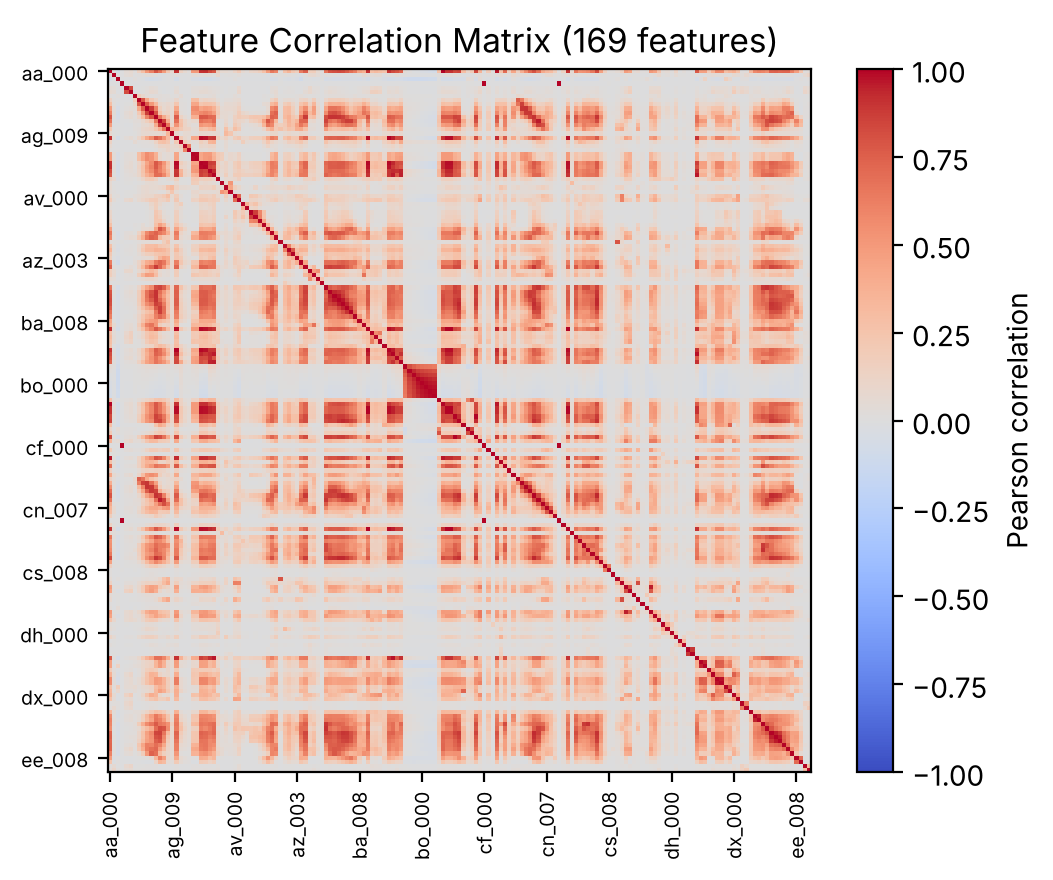

In [5]:
constant_cols = X_train_imp.columns[X_train_imp.nunique() <= 1].tolist()
print("Constant features excluded:", constant_cols)
corr_matrix = X_train_imp.drop(columns=constant_cols).corr()

fig, ax = plt.subplots(figsize=(5.6, 4.5))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ticks = np.arange(0, len(corr_matrix), 15)
ax.set_xticks(ticks, corr_matrix.columns[ticks], rotation=90, fontsize=7)
ax.set_yticks(ticks, corr_matrix.index[ticks], fontsize=7)
ax.set_title(f"Feature Correlation Matrix ({len(corr_matrix)} features)")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

Several blocks of features are strongly positively correlated (e.g., neighboring bins of the same histogram attribute), so many features carry overlapping information. Strong negative correlations are rare.

#### (iv) Features with the Highest CV

The $\lfloor\sqrt{170}\rfloor = 13$ features with the highest CV are used for visualization only; all 170 features are used for modeling. Box plots use a symmetric log scale.

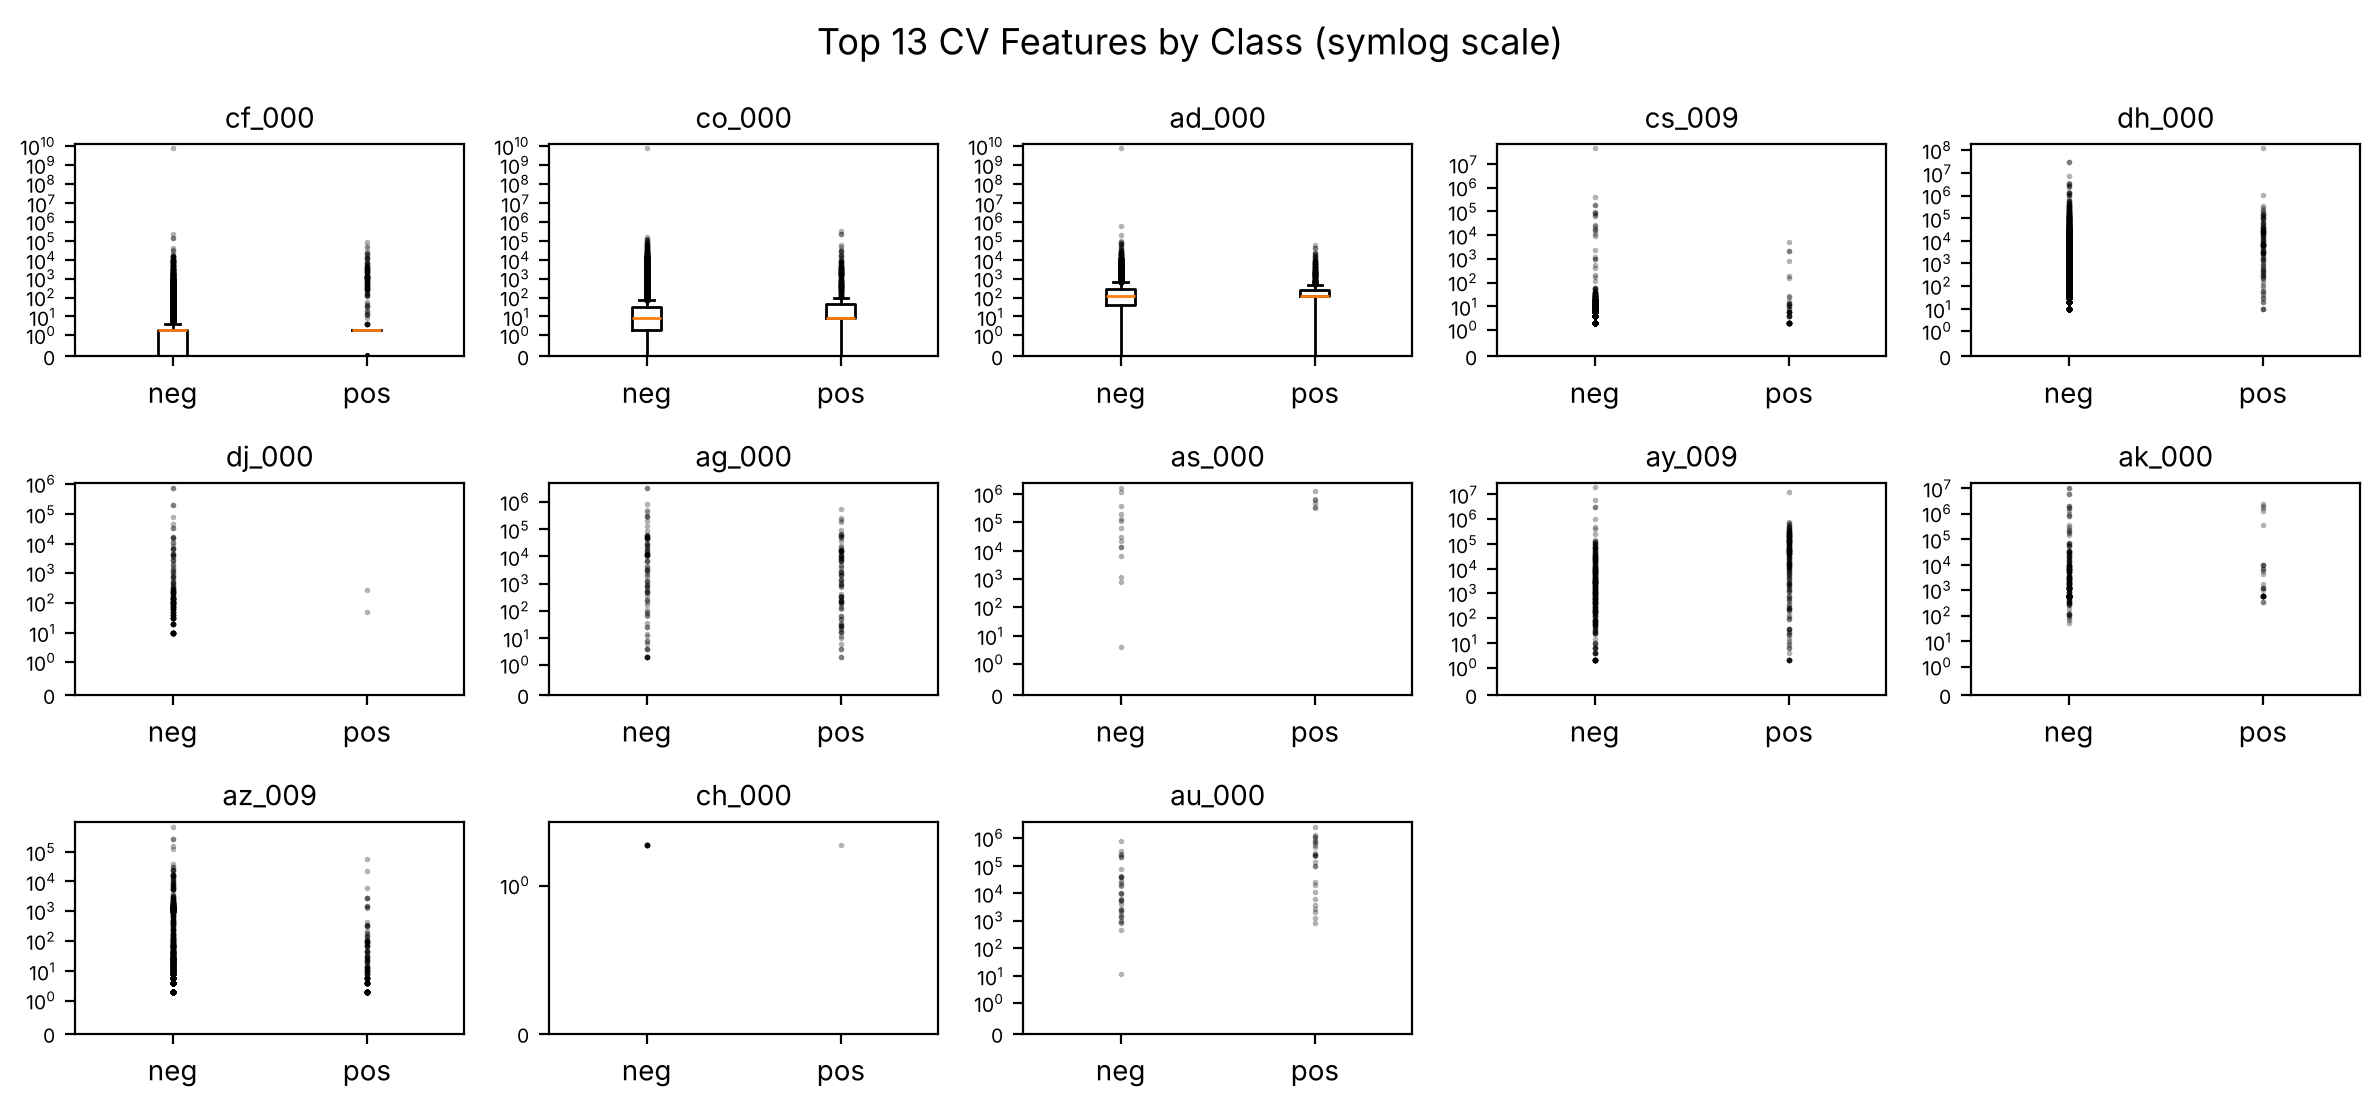

In [6]:
top_features = cv_table.head(13).index.tolist()

fig, axes = plt.subplots(3, 5, figsize=(12, 5.6))
for ax, feature in zip(axes.ravel(), top_features):
    ax.boxplot([X_train_imp.loc[y_train == k, feature] for k in (0, 1)],
               flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
    ax.set_xticks([1, 2], ["neg", "pos"])
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(0, max(1, X_train_imp[feature].max() * 1.5))
    ax.tick_params(axis="y", labelsize=7)
    ax.set_title(feature, fontsize=10)
for ax in axes.ravel()[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Top 13 CV Features by Class (symlog scale)", fontsize=13)
plt.tight_layout()
plt.show()

For the scatter plot matrix, I sampled 2,000 negatives and kept all 1,000 positives, and plotted $\log(1+x)$. Diagonal panels show class-wise histograms.

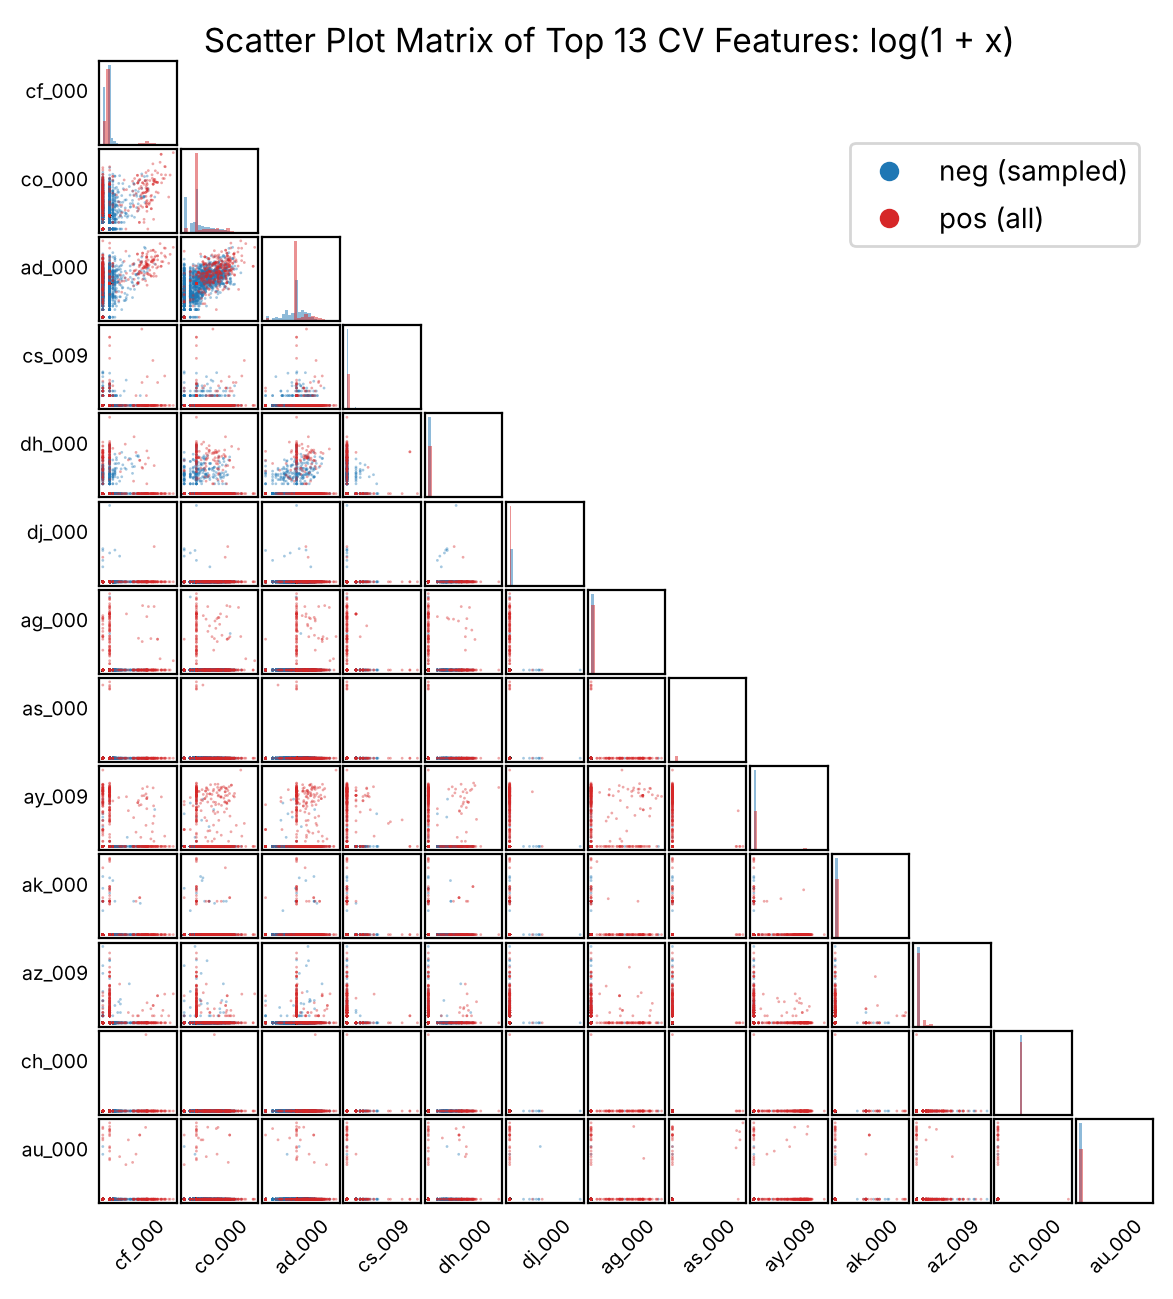

In [7]:
neg_index = y_train[y_train == 0].sample(n=2000, random_state=SEED).index
plot_index = neg_index.append(y_train[y_train == 1].index)   # positives drawn on top
plot_data = np.log1p(X_train_imp.loc[plot_index, top_features])
plot_labels = y_train.loc[plot_index]
colors = np.where(plot_labels == 1, "tab:red", "tab:blue")

k = len(top_features)
fig, axes = plt.subplots(k, k, figsize=(6.8, 6.8))
for i, fi in enumerate(top_features):
    for j, fj in enumerate(top_features):
        ax = axes[i, j]
        if j > i:
            ax.set_visible(False)
        elif i == j:
            for label, color in [(0, "tab:blue"), (1, "tab:red")]:
                ax.hist(plot_data.loc[plot_labels == label, fi], bins=20,
                        color=color, alpha=0.5, density=True)
        else:
            ax.scatter(plot_data[fj], plot_data[fi], c=colors, s=1, alpha=0.4, edgecolors="none")
        ax.set(xticks=[], yticks=[])
        if i == k - 1:
            ax.set_xlabel(fj, fontsize=7, rotation=45)
        if j == 0:
            ax.set_ylabel(fi, fontsize=7, rotation=0, ha="right")

handles = [plt.Line2D([], [], marker="o", ls="", color=c) for c in ["tab:blue", "tab:red"]]
fig.legend(handles, ["neg (sampled)", "pos (all)"], loc="upper right", bbox_to_anchor=(0.9, 0.9))
fig.suptitle("Scatter Plot Matrix of Top 13 CV Features: log(1 + x)", fontsize=12)
plt.subplots_adjust(wspace=0.05, hspace=0.05, top=0.95)
plt.show()

The classes overlap heavily and most values are at or near zero, so no single feature or pair clearly separates them. Two cautions:

1. The class differences in cf_000, co_000 and ad_000 are partly an **imputation artifact**: these features are missing for 64.5% of positives vs. 24.1% of negatives in the training set, so many positives sit exactly at the imputed median (the vertical red stripes).
2. The top three CVs are driven by a **single extreme row** (about $8.58\times10^9$).

Therefore, the scatter plots alone cannot establish the significance of these features; a high CV indicates high relative variability, not predictive power.

#### (v) Class Imbalance

In [8]:
class_counts = pd.DataFrame({
    "Training": train["class"].value_counts(),
    "Test": test["class"].value_counts()
}).reindex(["neg", "pos"])

class_counts

,Training,Test
class,,
neg,59000,15625
pos,1000,375


The training set contains 59,000 negative and 1,000 positive observations,
a ratio of 59:1. Positive observations account for only 1.67% of the
training set, so the dataset is severely imbalanced. Predicting every
training observation as negative would achieve 98.33% accuracy, showing
why accuracy alone can be misleading.

### (c) Random Forest Without Class Imbalance Compensation

500 trees, all 170 features, no class weighting or resampling. The helper functions below are reused in (d).

Training time: 184.2 s


OOB error: 0.0058   Test error: 0.0077


Error     AUC  Recall (pos)   FN  FP
Model Set                                            
RF    Training  0.0000  1.0000        1.0000    0   0
      Test      0.0077  0.9943        0.7227  104  19

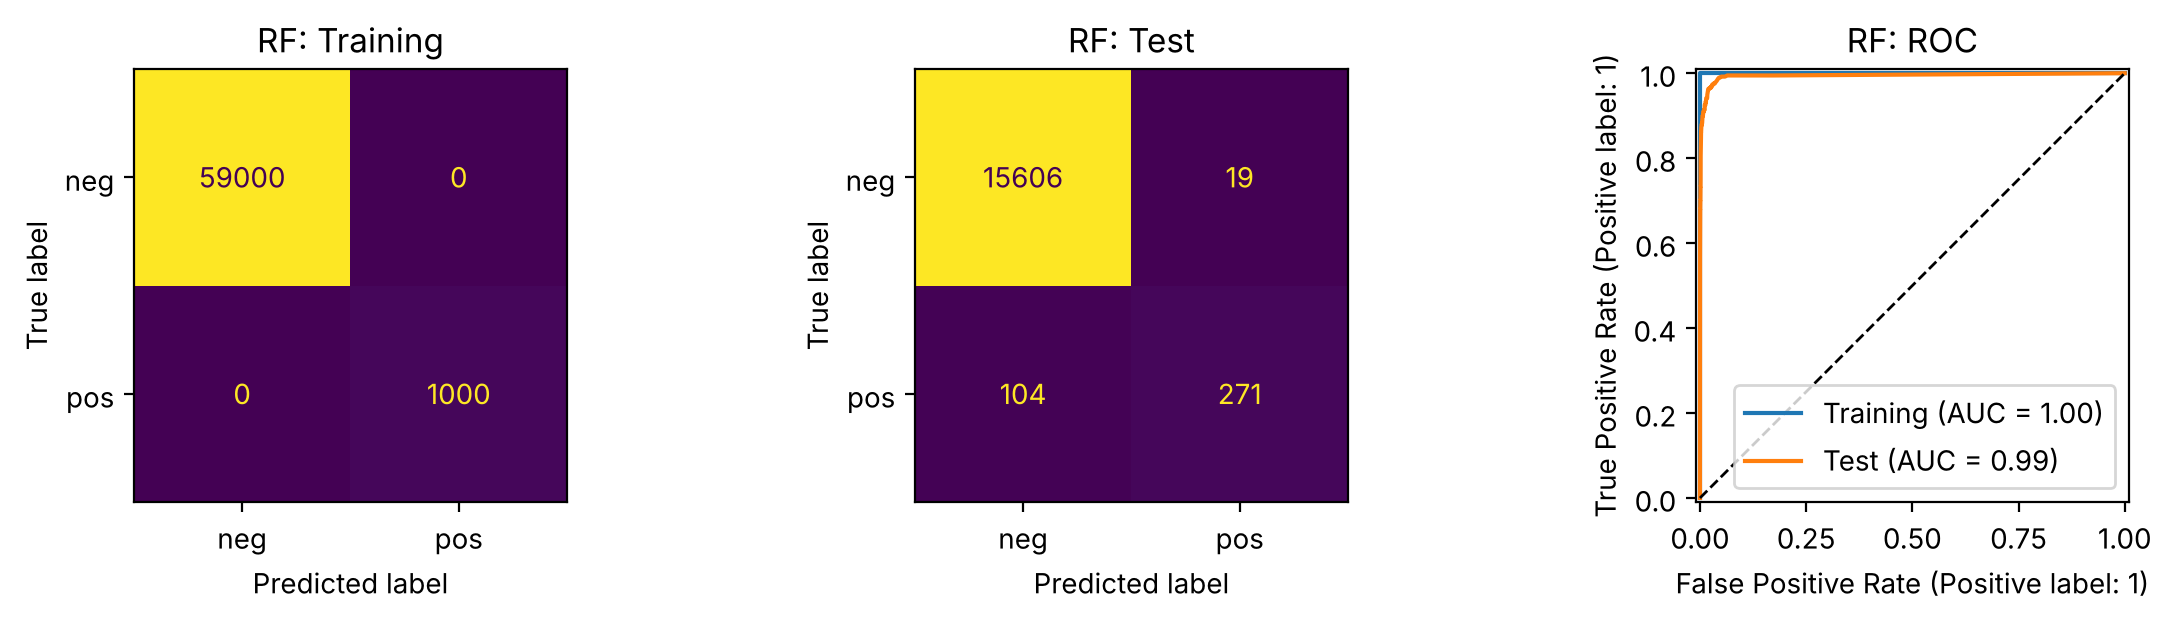

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
from time import perf_counter

def evaluate(model, name):
    """Error, AUC, positive-class recall, FN and FP on the training and test sets."""
    rows, curves = [], {}
    for set_name, X, y in [("Training", X_train_imp, y_train), ("Test", X_test_imp, y_test)]:
        prob, pred = model.predict_proba(X)[:, 1], model.predict(X)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        rows.append({"Model": name, "Set": set_name, "Error": (fp + fn) / len(y),
                     "AUC": roc_auc_score(y, prob), "Recall (pos)": tp / (tp + fn),
                     "FN": fn, "FP": fp})
        curves[set_name] = (y, pred, prob)
    return pd.DataFrame(rows).set_index(["Model", "Set"]), curves

def plot_results(curves, title):
    """Training/test confusion matrices and ROC curves."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for ax, (set_name, (y, pred, prob)) in zip(axes, curves.items()):
        ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["neg", "pos"],
                                                ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{title}: {set_name}")
        RocCurveDisplay.from_predictions(y, prob, name=set_name, ax=axes[2])
    axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[2].set_title(f"{title}: ROC")
    plt.tight_layout()
    plt.show()

rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", oob_score=True,
                            random_state=SEED, n_jobs=-1)
start = perf_counter()
rf.fit(X_train_imp, y_train)
print(f"Training time: {perf_counter() - start:.1f} s")

rf_results, rf_curves = evaluate(rf, "RF")
print(f"OOB error: {1 - rf.oob_score_:.4f}   "
      f"Test error: {rf_results.loc[('RF', 'Test'), 'Error']:.4f}")
display(rf_results.round(4))
plot_results(rf_curves, "RF")

Training error is 0 and training AUC is 1, as expected, because each tree has seen most training points; this is not an honest error estimate. The **OOB error (0.0058) is close to, but lower than, the test error (0.0077)**. Part of the gap is because the test set has a higher positive rate (2.34% vs. 1.67%) and most errors come from positives.

Despite a test AUC of 0.9943, the model missed 104 of 375 test positives (recall 72.3%): without compensation, the 0.5 threshold favors the majority class.

### (d) Random Forest With Class Imbalance Compensation

Random forests usually address class imbalance in two ways (Chen, Liaw & Breiman, 2004, *Using Random Forest to Learn Imbalanced Data*):

- Weighted RF: give the minority class a larger weight in the split criterion and leaf votes.
- Balanced RF: draw each tree's sample so both classes are equally represented, by undersampling the majority class.

Threshold adjustment and oversampling (e.g., SMOTE) are other options. I tried both methods: `class_weight="balanced"` (each positive weighted 59× a negative) and imblearn's `BalancedRandomForestClassifier` (each tree uses all 1,000 positives and 1,000 random negatives). All other settings match (c).

In [10]:
import warnings
from imblearn.ensemble import BalancedRandomForestClassifier
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")

models = {
    "Weighted RF": RandomForestClassifier(
        n_estimators=500, max_features="sqrt", class_weight="balanced",
        oob_score=True, random_state=SEED, n_jobs=-1),
    "Balanced RF": BalancedRandomForestClassifier(
        n_estimators=500, max_features="sqrt", sampling_strategy="auto", replacement=False,
        bootstrap=True, oob_score=True, random_state=SEED, n_jobs=-1)
}

results, curves, oob = [rf_results], {}, {"RF": 1 - rf.oob_score_}
for name, model in models.items():
    model.fit(X_train_imp, y_train)
    res, curves[name] = evaluate(model, name)
    results.append(res)
    oob[name] = 1 - model.oob_score_

display(pd.concat(results).round(4))
pd.DataFrame({"OOB error": oob,
              "Test error": {r.index[1][0]: r.iloc[1]["Error"] for r in results}}).round(4)

Error     AUC  Recall (pos)   FN    FP
Model       Set                                              
RF          Training  0.0000  1.0000        1.0000    0     0
            Test      0.0077  0.9943        0.7227  104    19
Weighted RF Training  0.0000  1.0000        1.0000    0     0
            Test      0.0107  0.9933        0.5787  158    14
Balanced RF Training  0.0545  0.9977        1.0000    0  3268
            Test      0.0522  0.9924        0.9840    6   830

,OOB error,Test error
RF,0.0058,0.0077
Weighted RF,0.0076,0.0107
Balanced RF,0.0546,0.0522


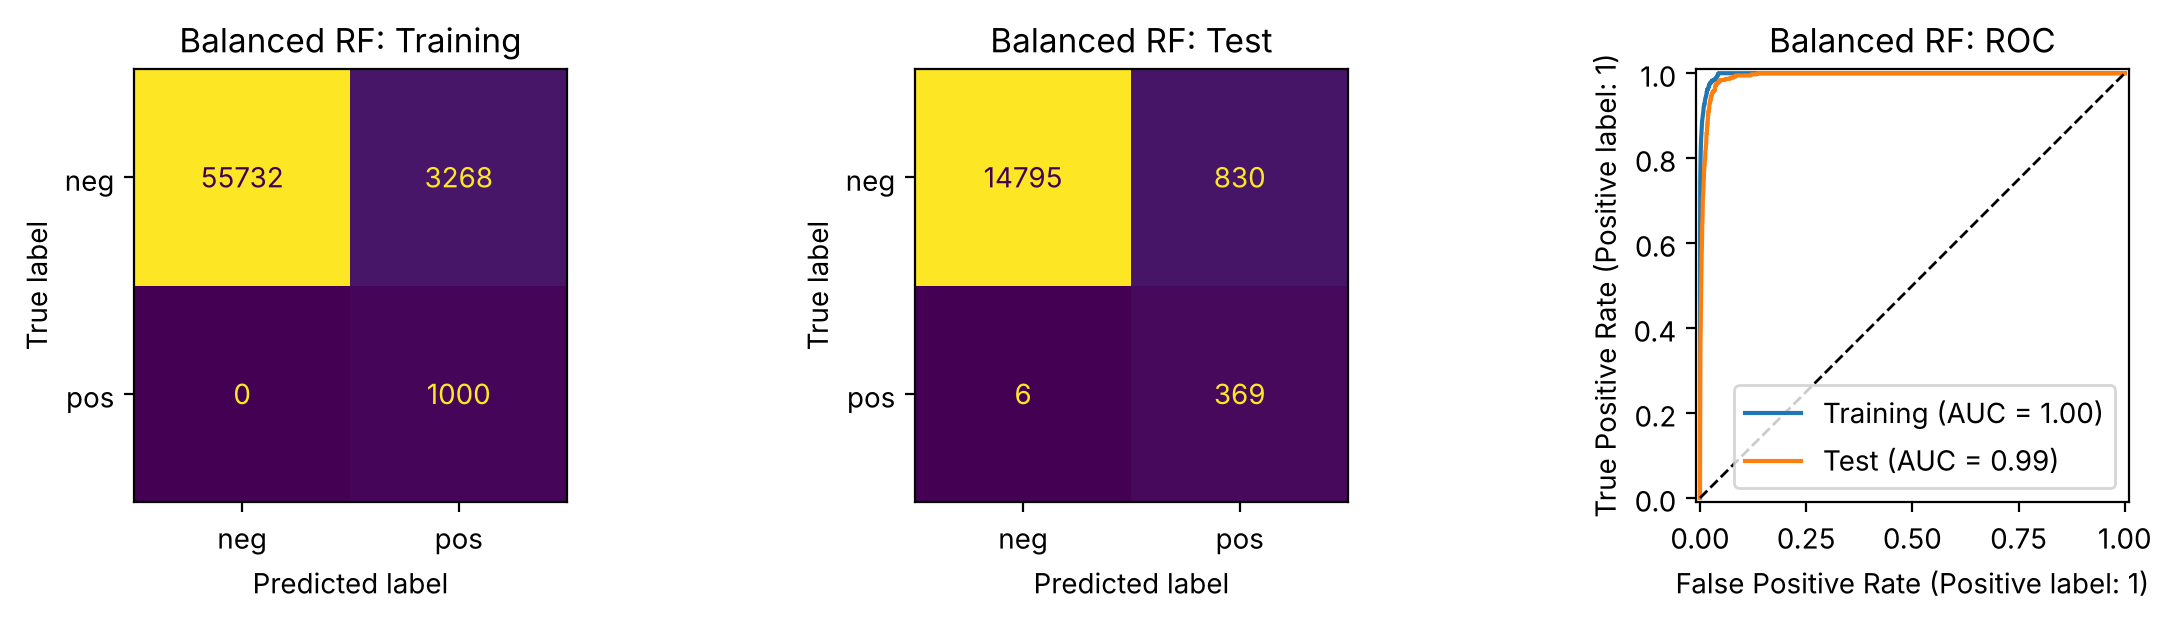

In [11]:
plot_results(curves["Balanced RF"], "Balanced RF")

- **Weighted RF did not help** (test recall 72.3% → 57.9%, FN 104 → 158). The trees are fully grown, so leaves are almost pure and class weights barely change the leaf votes; they only alter the splits.
- **Balanced RF worked**: test recall rose to 98.4% (FN 104 → 6), at the cost of more false positives (19 → 830), so the overall error rose to 0.0522. This trade-off is preferable for APS, where missing a failure is much more costly than a false alarm.
- Test AUC is almost unchanged across models (0.992–0.994): compensation mainly shifts the operating point rather than improving the ranking. Accuracy is therefore a poor criterion here; recall and FN counts are more informative.
- For every model, the OOB error remains a reasonable estimate of the test error.

### (e) XGBoost and Model Trees

XGBoost does not fit a true model tree with a logistic model at each node; its splits are still univariate. The closest approximation is XGBoost with the logistic loss (`binary:logistic`): each tree is fit to the gradient of the logistic loss, and the L1 penalty `reg_alpha` ($\alpha$) shrinks the leaf weights.

I chose $\alpha \in \{0, 0.1, 1, 10, 100\}$ by 5-fold stratified cross-validation, using the CV log loss (the logistic-regression loss) as the criterion. Other settings are fixed (300 trees, learning rate 0.1, max depth 6). The imputed data from (b) are used, and no class imbalance compensation is applied.

In [12]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
xgb_base = XGBClassifier(objective="binary:logistic", booster="gbtree", n_estimators=300,
                         learning_rate=0.1, max_depth=6, tree_method="hist",
                         eval_metric="logloss", random_state=SEED, n_jobs=-1)
SCORING = {"LogLoss": "neg_log_loss", "AUC": "roc_auc", "Accuracy": "accuracy"}
ALPHAS = [0, 0.1, 1, 10, 100]

def alpha_table(search, param):
    res = pd.DataFrame(search.cv_results_)
    return pd.DataFrame({"alpha": res[f"param_{param}"],
                         "CV Log Loss": -res["mean_test_LogLoss"],
                         "CV AUC": res["mean_test_AUC"],
                         "CV Error": 1 - res["mean_test_Accuracy"]})

xgb_search = GridSearchCV(xgb_base, {"reg_alpha": ALPHAS}, scoring=SCORING,
                          refit="LogLoss", cv=cv5, n_jobs=1)
start = perf_counter()
xgb_search.fit(X_train_imp, y_train)
print(f"5-fold CV time: {perf_counter() - start:.1f} s")

xgb_cv = alpha_table(xgb_search, "reg_alpha")
xgb_cv.round(4)

5-fold CV time: 124.8 s


,alpha,CV Log Loss,CV AUC,CV Error
0,0.0,0.0203,0.9890,0.0052
1,0.1,0.0205,0.9888,0.0054
2,1.0,0.0198,0.9893,0.0054
3,10.0,0.0211,0.9893,0.0071
4,100.0,0.0325,0.9820,0.0110


Best alpha: 1   5-fold CV error: 0.00538   Test error: 0.00625


Error     AUC  Recall (pos)  FN  FP
Model   Set                                           
XGBoost Training  0.0000  1.0000        0.9990   1   0
        Test      0.0062  0.9958        0.7787  83  17

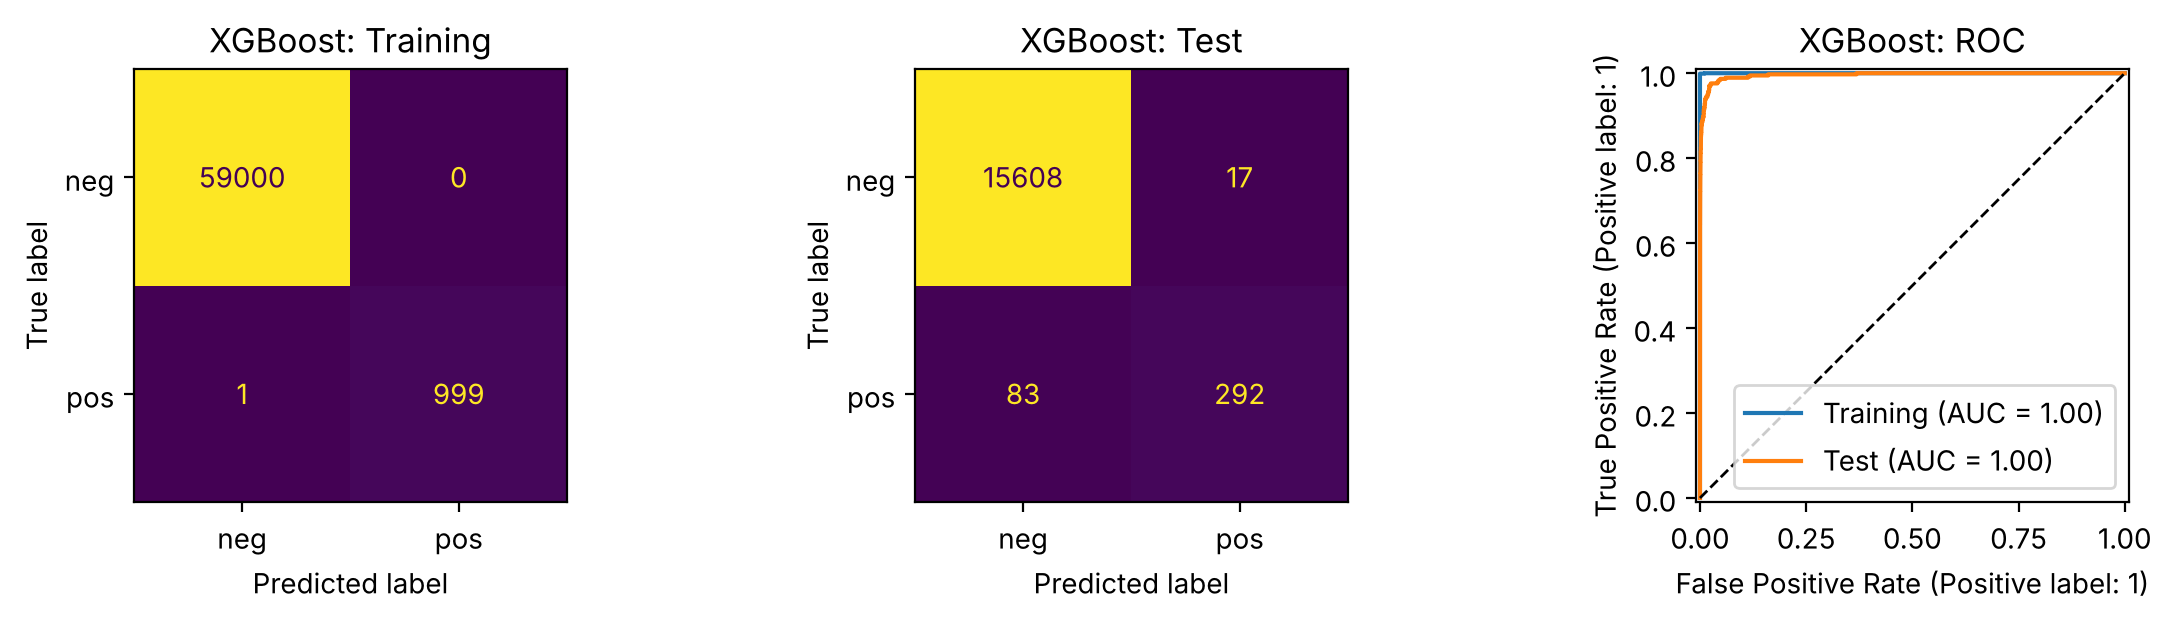

In [13]:
xgb_model = xgb_search.best_estimator_
cv_error = xgb_cv.loc[xgb_search.best_index_, "CV Error"]
xgb_results, xgb_curves = evaluate(xgb_model, "XGBoost")

print(f"Best alpha: {xgb_search.best_params_['reg_alpha']}   5-fold CV error: {cv_error:.5f}   "
      f"Test error: {xgb_results.loc[('XGBoost', 'Test'), 'Error']:.5f}")
display(xgb_results.round(4))
plot_results(xgb_curves, "XGBoost")

- $\alpha = 1$ gives the lowest CV log loss (0.0198) and a near-best CV AUC. Results are fairly insensitive for $\alpha \le 10$, while $\alpha = 100$ over-regularizes and clearly worsens every metric.
- The **5-fold CV error (0.00538) is close to the test error (0.00625)**. The test error is slightly higher, partly because the test set has a higher positive rate; the CV error is also slightly optimistic because the same folds were used to choose $\alpha$.
- Training error is almost 0 (1 false negative), so the boosted model fits the training data nearly perfectly.
- Compared with the uncompensated RF in (c), XGBoost has a lower test error (0.00625 vs. 0.0077) and a higher test AUC (0.9958 vs. 0.9943). Without compensation, however, it still misses 83 of 375 test positives (recall 77.9%).

### (f) XGBoost With SMOTE

SMOTE creates synthetic positives by interpolating between each positive observation and one of its $k=5$ nearest positive neighbors, until both classes have 59,000 training observations. The full training set is used (no downsampling).

**Right vs. wrong cross-validation.** SMOTE must be applied only to the training folds. If it is applied to the whole training set before splitting, synthetic points generated from validation positives leak into the training folds, and the validation folds also contain synthetic points, so the CV error becomes too optimistic. I used an imblearn Pipeline, which applies SMOTE only when fitting and never to validation or test data. $\alpha$ is selected as in (e). Training-set metrics are computed on the original training data, which contains no synthetic points.

In [14]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

smote_pipe = Pipeline([("smote", SMOTE(random_state=SEED)), ("xgb", xgb_base)])
smote_search = GridSearchCV(smote_pipe, {"xgb__reg_alpha": ALPHAS}, scoring=SCORING,
                            refit="LogLoss", cv=cv5, n_jobs=1)
start = perf_counter()
smote_search.fit(X_train_imp, y_train)
print(f"5-fold CV time: {perf_counter() - start:.1f} s")

smote_cv = alpha_table(smote_search, "xgb__reg_alpha")
smote_cv.round(4)

5-fold CV time: 308.7 s


,alpha,CV Log Loss,CV AUC,CV Error
0,0.0,0.0229,0.9880,0.0064
1,0.1,0.0227,0.9875,0.0065
2,1.0,0.0223,0.9876,0.0062
3,10.0,0.0236,0.9863,0.0075
4,100.0,0.0495,0.9844,0.0183


Best alpha: 1   5-fold CV error: 0.00622   Test error: 0.00750


Error     AUC  Recall (pos)  FN  FP
Model           Set                                           
XGBoost         Training  0.0000  1.0000        0.9990   1   0
                Test      0.0062  0.9958        0.7787  83  17
XGBoost + SMOTE Training  0.0000  1.0000        0.9990   1   0
                Test      0.0075  0.9944        0.8560  54  66

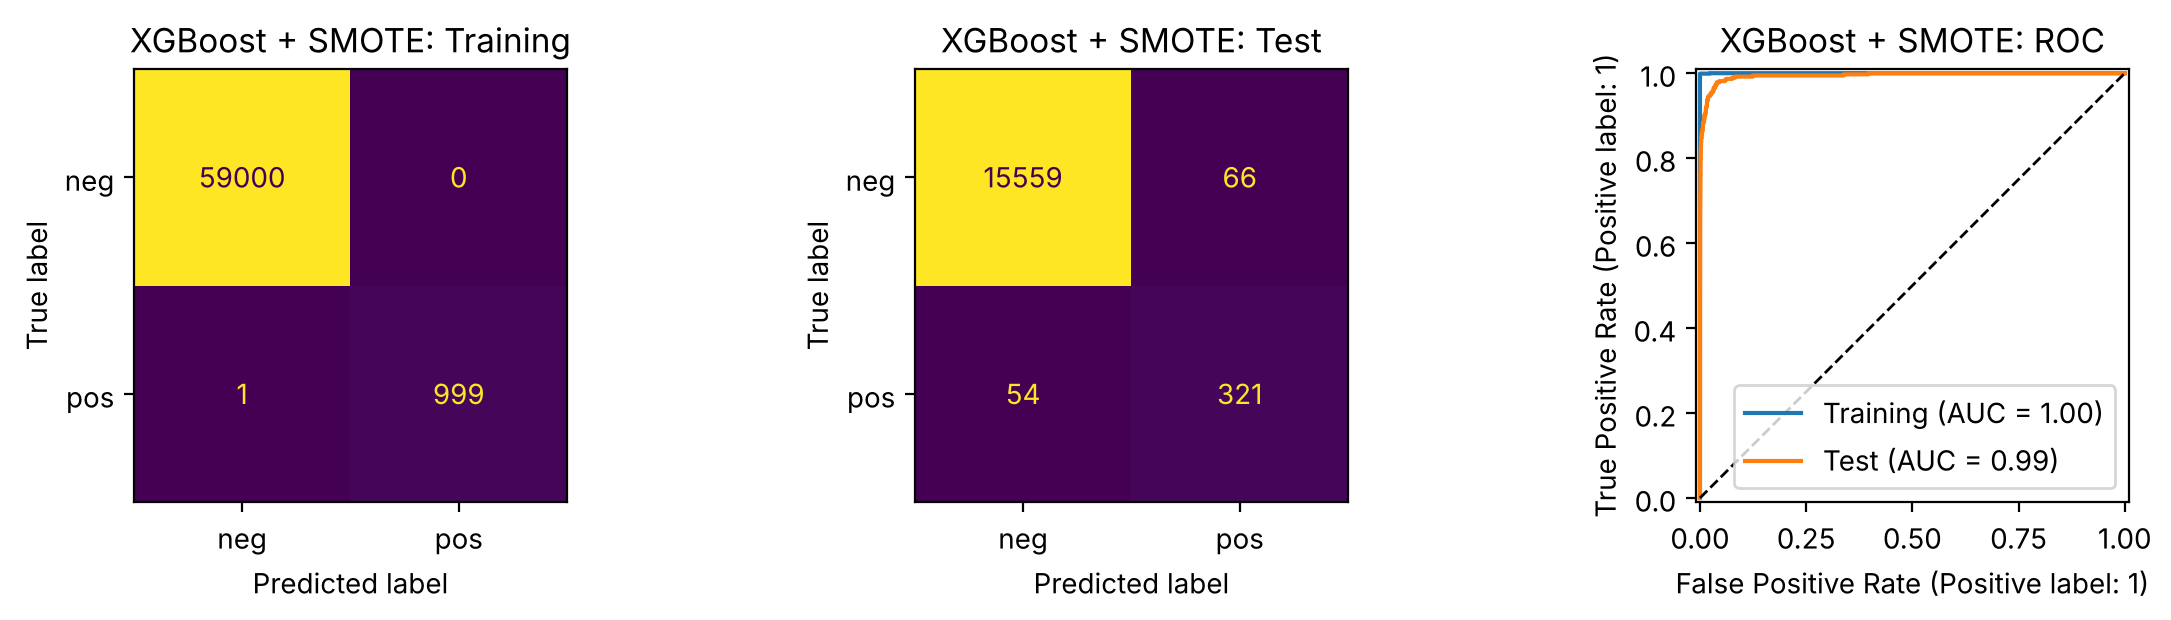

In [15]:
smote_model = smote_search.best_estimator_
smote_cv_error = smote_cv.loc[smote_search.best_index_, "CV Error"]
smote_results, smote_curves = evaluate(smote_model, "XGBoost + SMOTE")

print(f"Best alpha: {smote_search.best_params_['xgb__reg_alpha']}   "
      f"5-fold CV error: {smote_cv_error:.5f}   "
      f"Test error: {smote_results.loc[('XGBoost + SMOTE', 'Test'), 'Error']:.5f}")
display(pd.concat([xgb_results, smote_results]).round(4))
plot_results(smote_curves, "XGBoost + SMOTE")

In [16]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Wrong way (for comparison only): SMOTE the whole training set, then cross-validate
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_train_imp, y_train)
wrong = cross_validate(clone(xgb_base).set_params(reg_alpha=1), X_sm, y_sm, cv=cv5,
                       scoring={"AUC": "roc_auc", "Accuracy": "accuracy"})

pd.DataFrame({
    "CV AUC": [smote_cv.loc[smote_search.best_index_, "CV AUC"], wrong["test_AUC"].mean()],
    "CV Error": [smote_cv_error, 1 - wrong["test_Accuracy"].mean()]
}, index=["Right: SMOTE inside each fold", "Wrong: SMOTE before CV"]).round(4)

,CV AUC,CV Error
Right: SMOTE inside each fold,0.9876,0.0062
Wrong: SMOTE before CV,1.0000,0.0023


- With SMOTE, $\alpha = 1$ is again selected (CV log loss 0.0223); $\alpha = 100$ again over-regularizes.
- The **5-fold CV error (0.00622) is close to the test error (0.00750)**, so the correctly cross-validated estimate is reasonable. The wrong approach gives a CV error of 0.0023 and an AUC of 1.0000, which is clearly over-optimistic. Its validation folds are also half synthetic positives, so they do not reflect the real class ratio.
- **Uncompensated vs. SMOTE (test set):** recall rises from 77.9% to 85.6% (FN 83 → 54), while false positives rise from 17 to 66. The overall error rises slightly (0.0062 → 0.0075), and the AUC is almost unchanged (0.9958 vs. 0.9944).
- As with the balanced RF in (d), SMOTE mainly shifts the operating point toward the minority class: it detects more failures at the cost of more false alarms, which is preferable when a missed failure is costly. Compared with the balanced RF (FN 6, FP 830), SMOTE gives a more moderate trade-off.

## 2. ISLR 6.6.3

Increasing s relaxes the constraint on the sum of the absolute
coefficients, making the model more flexible.

**(a) iv. Steadily decrease.** The feasible set expands as s increases,
so the minimum training RSS cannot increase. Once a least-squares
solution becomes feasible, the training RSS remains constant.

**(b) ii. Decrease initially, then increase in a U shape.** Initially,
relaxing the constraint reduces bias and can improve test performance.
With greater flexibility, increased variance can eventually raise
the test RSS.

**(c) iii. Steadily increase.** The less constrained model is generally
more sensitive to changes in the training data.

**(d) iv. Steadily decrease.** Relaxing the constraint generally reduces
the squared bias caused by coefficient shrinkage.

**(e) v. Remain constant.** Irreducible error comes from noise in the
data-generating process and does not depend on s.

These describe the usual bias–variance trends; the test RSS need not
follow a perfect U shape in every finite dataset.

## 3. ISLR 6.6.5

Let $z_i=x_{i1}=x_{i2}$ ($i=1,2$). Since the data are centered, $\hat\beta_0=0$, and the RSS depends only on $t=\beta_1+\beta_2$: $\ \text{RSS}=\sum_{i=1}^{2}(y_i-z_it)^2$.

**(a)** Ridge: $\displaystyle\min_{\beta_1,\beta_2}\ \sum_{i=1}^{2}\left[y_i-z_i(\beta_1+\beta_2)\right]^2+\lambda(\beta_1^2+\beta_2^2)$.

**(b)** For a fixed $t$, $\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}$, which is minimized only when $\beta_1=\beta_2=t/2$. Hence, for $\lambda>0$, $\hat\beta_1=\hat\beta_2$.

**(c)** Lasso: $\displaystyle\min_{\beta_1,\beta_2}\ \sum_{i=1}^{2}\left[y_i-z_i(\beta_1+\beta_2)\right]^2+\lambda(|\beta_1|+|\beta_2|)$.

**(d)** By the triangle inequality, $|\beta_1|+|\beta_2|\ge|t|$, with equality whenever $\beta_1$ and $\beta_2$ have the same sign (or one is zero). So the problem reduces to finding $t^*=\arg\min_t\sum_i(y_i-z_it)^2+\lambda|t|$. If $t^*\neq0$, every pair $(\hat\beta_1,\hat\beta_2)=(at^*,(1-a)t^*)$ with $0\le a\le1$ has the same RSS and the same penalty, e.g., $(t^*,0)$, $(0,t^*)$ and $(t^*/2,t^*/2)$. The solutions form a line segment, so the lasso cannot uniquely split the effect between the identical predictors. (If $\lambda$ is large enough that $t^*=0$, the unique solution is $(0,0)$.)

## 4. ISLR 8.4.5

**Majority vote:** 6 of the 10 estimates exceed 0.5, so 6 trees vote Red and 4 vote Green; the prediction is **Red**.

**Average probability:** $\bar p=(0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75)/10=0.45<0.5$, so the prediction is **Green**.

The results differ because majority voting counts only each tree's class, while averaging also uses the magnitude of each estimated probability.

## 5. ISLR 9.7.3

**(a)** The observations are plotted below (left).

**(b)** The closest parallel supporting lines are $X_2=X_1$ (Red) and $X_2=X_1-1$ (Blue). The optimal separating hyperplane lies halfway between them: $0.5-X_1+X_2=0$.

**(c)** Classify to Red if $0.5-X_1+X_2>0$, and to Blue otherwise; i.e., $\beta_0=0.5,\ \beta_1=-1,\ \beta_2=1$.

**(d)** The margin is $M=0.5/\sqrt{(-1)^2+1^2}=1/(2\sqrt2)\approx0.354$ (shaded band; full width $2M\approx0.707$).

**(e)** The support vectors are observations 2, 3, 5 and 6: $(2,2)$, $(4,4)$, $(2,1)$, $(4,3)$.

**(f)** Observation 7, $(4,1)$, is far outside the margin (distance $2.5/\sqrt2$) and is not a support vector, so a slight movement does not change the maximal margin hyperplane.

**(g)** $0.25-X_1+X_2=0$ separates the classes but is not optimal: its margin is only $0.25/\sqrt2<M$ (right plot).

**(h)** Adding a Blue observation at $(2,3)$ makes the classes non-separable, because $(2,3)=\tfrac14(3,4)+\tfrac12(2,2)+\tfrac14(1,4)$ lies inside the convex hull of the Red points (right plot).

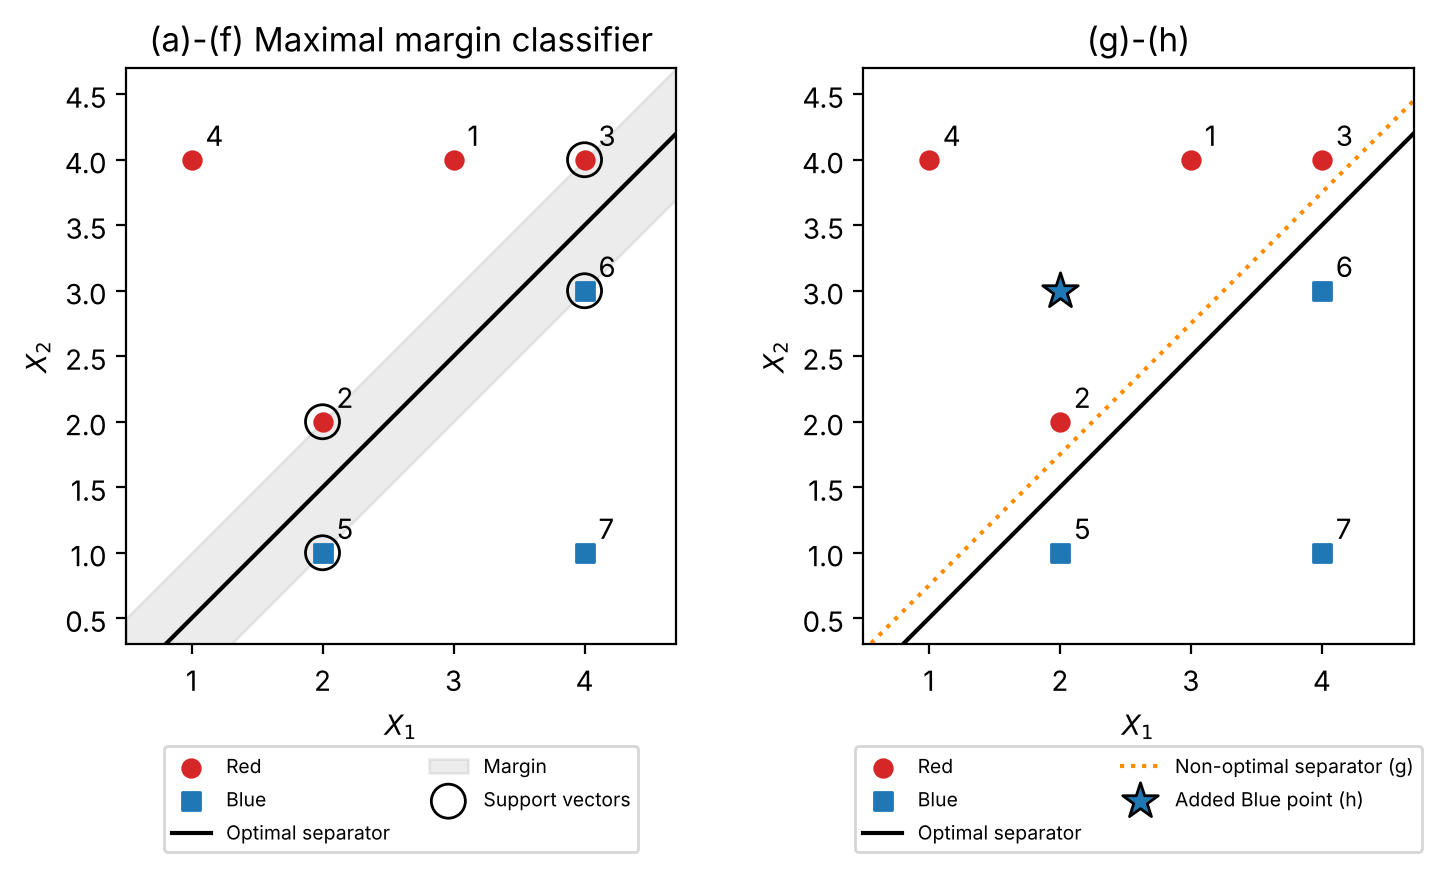

In [17]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
x = np.linspace(0.5, 4.7, 100)

fig, axes = plt.subplots(1, 2, figsize=(7.6, 4.1))
for ax in axes:
    ax.scatter(*points[:4].T, color="tab:red", s=40, label="Red", zorder=3)
    ax.scatter(*points[4:].T, color="tab:blue", marker="s", s=40, label="Blue", zorder=3)
    for n, (x1, x2) in enumerate(points, start=1):
        ax.annotate(str(n), (x1, x2), xytext=(5, 5), textcoords="offset points")
    ax.plot(x, x - 0.5, "k", label="Optimal separator")
    ax.set(xlabel="$X_1$", ylabel="$X_2$", xlim=(0.5, 4.7), ylim=(0.3, 4.7), aspect="equal")

axes[0].fill_between(x, x - 1, x, color="gray", alpha=0.15, label="Margin")
axes[0].scatter(*points[[1, 2, 4, 5]].T, s=150, facecolors="none", edgecolors="k",
                label="Support vectors")
axes[0].set_title("(a)-(f) Maximal margin classifier")
axes[1].plot(x, x - 0.25, ":", color="darkorange", label="Non-optimal separator (g)")
axes[1].scatter(2, 3, marker="*", s=180, color="tab:blue", edgecolors="k",
                label="Added Blue point (h)")
axes[1].set_title("(g)-(h)")
for ax in axes:
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout()
plt.show()

## 6. Extra Practice
### ISLR 5.4.2

**(a)** Each draw selects observation $j$ with probability $1/n$, so the first draw is not $j$ with probability $1-1/n$.

**(b)** Sampling is with replacement, so the second draw is also not $j$ with probability $1-1/n$.

**(c)** The $n$ draws are independent, so $P(j\text{ not in the sample})=(1-1/n)^n$.

**(d)–(f)** $P(j\text{ in the sample})=1-(1-1/n)^n$: $0.67232$ for $n=5$, $0.63397$ for $n=100$, and $0.63214$ for $n=10{,}000$.

**(g)** As $n$ grows, the probability decreases quickly toward $1-e^{-1}\approx0.632$, so a bootstrap sample contains about 63.2% of the distinct original observations (plot below, log-scale $x$-axis).

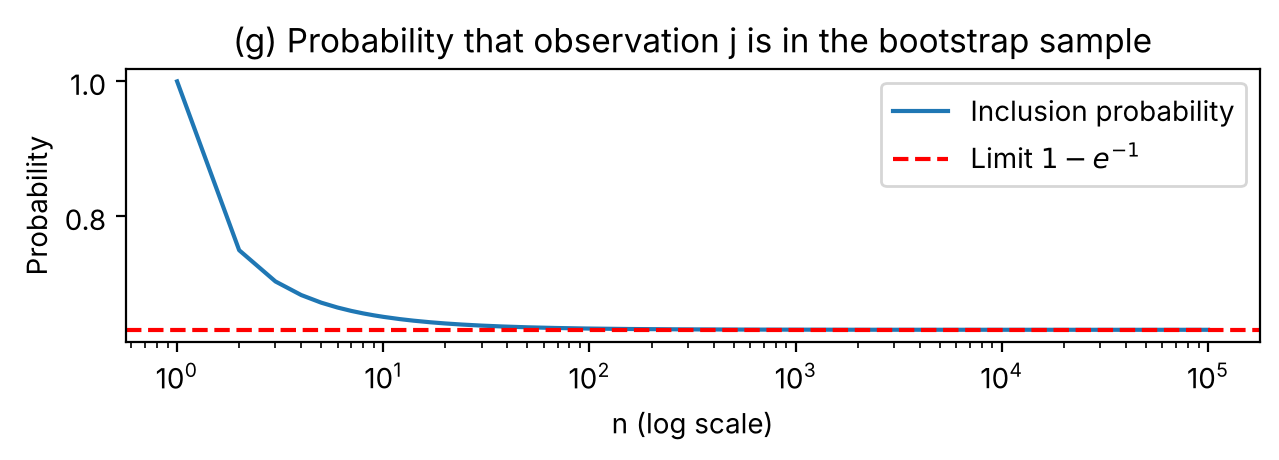

Theoretical: 0.63397   Simulated: 0.63040


In [18]:
n_values = np.arange(1, 100001)
fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.plot(n_values, 1 - (1 - 1 / n_values) ** n_values, label="Inclusion probability")
ax.axhline(1 - np.exp(-1), color="red", ls="--", label=r"Limit $1-e^{-1}$")
ax.set(xscale="log", xlabel="n (log scale)", ylabel="Probability",
       title="(g) Probability that observation j is in the bootstrap sample")
ax.legend()
plt.tight_layout()
plt.show()

# (h) Simulation for n = 100 and observation j = 4
rng = np.random.default_rng(42)
included = np.array([np.any(rng.integers(1, 101, size=100) == 4) for _ in range(10000)])
print(f"Theoretical: {1 - 0.99 ** 100:.5f}   Simulated: {included.mean():.5f}")

**(h)** In 10,000 simulated bootstrap samples with $n=100$, observation 4
was included in 63.04% of the samples. This is close to the theoretical
probability of 63.397%. The small difference is consistent with Monte
Carlo variation.

### ISLR 6.6.4

*(Listed as 6.8.4 in the homework; this is the first-edition numbering of the same exercise.)*

Increasing $\lambda$ shrinks the coefficients toward zero, making the model less flexible.

**(a) iii. Steadily increase.** At $\lambda=0$ the fit is least squares, which minimizes the training RSS; more shrinkage moves the fit away from it.

**(b) ii. Decrease initially, then increase in a U shape.** Initially the reduction in variance outweighs the increase in bias; eventually the bias dominates and the test RSS rises.

**(c) iv. Steadily decrease.** A more constrained model is less sensitive to the training data.

**(d) iii. Steadily increase.** Shrinking the coefficients moves the fit further from the true relationship.

**(e) v. Remain constant.** The irreducible error does not depend on $\lambda$.

### ISLR 8.4.4

**(a)** First split at $X_1=1$; the right region predicts 5. Within the left region, split at $X_2=1$, giving 15 above the cut. Below it, split at $X_1=0$, giving 3 on the left. Finally, split the remaining region at $X_2=0$, giving 10 below and 0 above.

**(b)** The tree gives five regions: $X_2<1$ splits into $X_1<1$ (mean $-1.80$) and $X_1\ge1$ ($0.63$); $1\le X_2<2$ splits into $X_1<0$ ($-1.06$) and $X_1\ge0$ ($0.21$); and $X_2\ge2$ has mean $2.49$. In the tree below, "Yes" means the splitting condition is satisfied.

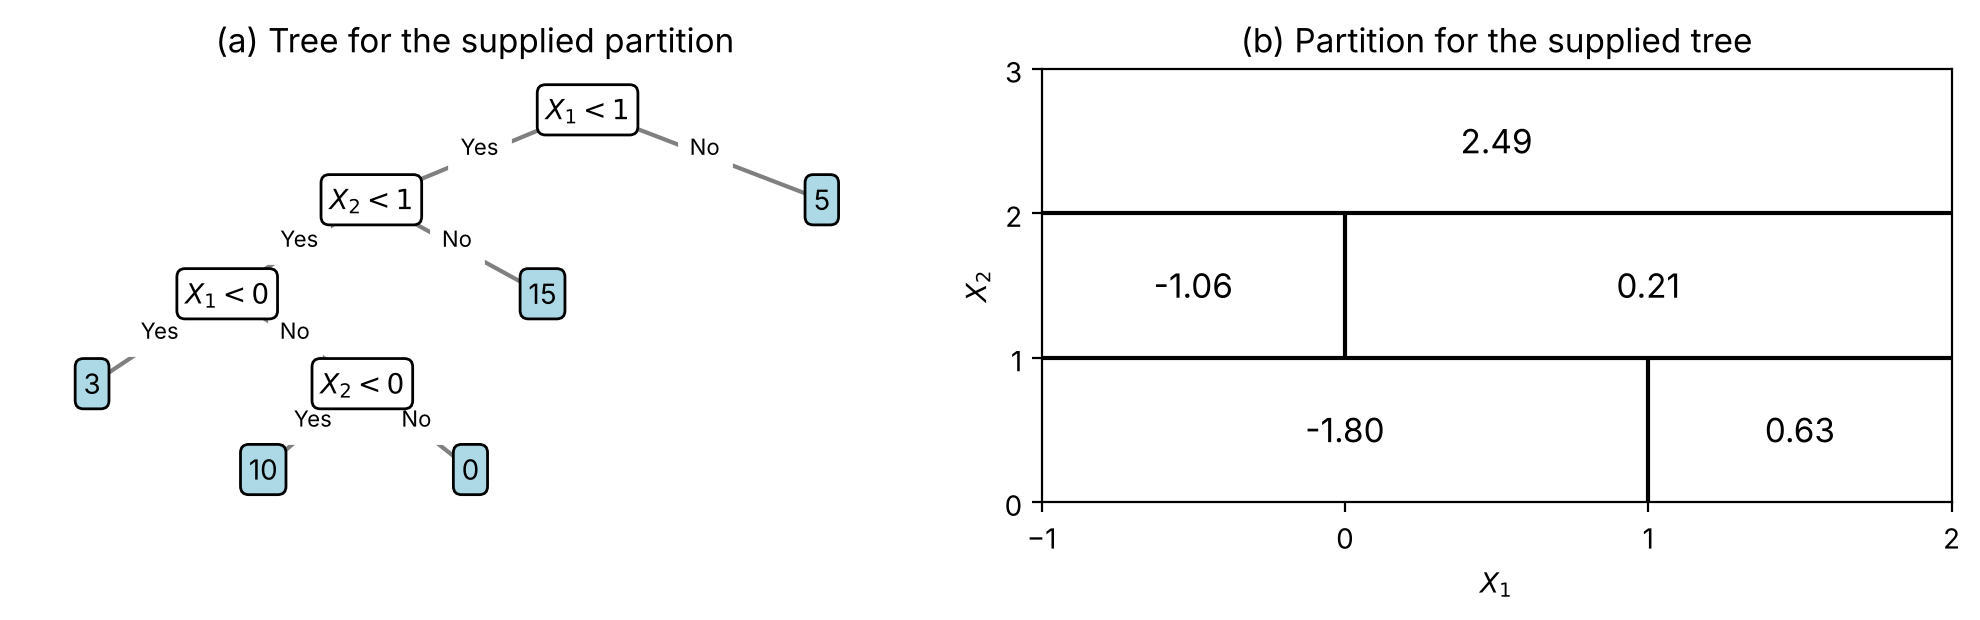

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

# (a) Tree: node -> (x, y, label); leaves are shaded
nodes = {"r": (0.6, 0.92, "$X_1<1$"), "a": (0.36, 0.7, "$X_2<1$"), "b": (0.2, 0.47, "$X_1<0$"),
         "c": (0.35, 0.25, "$X_2<0$"), "5": (0.86, 0.7, "5"), "15": (0.55, 0.47, "15"),
         "3": (0.05, 0.25, "3"), "10": (0.24, 0.04, "10"), "0": (0.47, 0.04, "0")}
edges = [("r", "a", "Yes"), ("r", "5", "No"), ("a", "b", "Yes"), ("a", "15", "No"),
         ("b", "3", "Yes"), ("b", "c", "No"), ("c", "10", "Yes"), ("c", "0", "No")]
ax = axes[0]
for p, c, ans in edges:
    (x1, y1, _), (x2, y2, _) = nodes[p], nodes[c]
    ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, ans, fontsize=8, ha="center", backgroundcolor="white")
for key, (x, y, label) in nodes.items():
    ax.text(x, y, label, ha="center", va="center", fontsize=10, zorder=3,
            bbox={"boxstyle": "round", "facecolor": "lightblue" if key.isdigit() else "white"})
ax.set(xlim=(-0.03, 0.98), ylim=(-0.04, 1.02), title="(a) Tree for the supplied partition")
ax.axis("off")

# (b) Partition for the supplied tree
ax = axes[1]
ax.hlines([1, 2], -1, 2, color="k")
ax.vlines(1, 0, 1, color="k")
ax.vlines(0, 1, 2, color="k")
for x, y, v in [(0, 0.5, "-1.80"), (1.5, 0.5, "0.63"), (-0.5, 1.5, "-1.06"),
                (1, 1.5, "0.21"), (0.5, 2.5, "2.49")]:
    ax.text(x, y, v, ha="center", va="center", fontsize=12)
ax.set(xlim=(-1, 2), ylim=(0, 3), xticks=[-1, 0, 1, 2], yticks=[0, 1, 2, 3],
       xlabel="$X_1$", ylabel="$X_2$", title="(b) Partition for the supplied tree")
plt.tight_layout()
plt.show()

### ISLR 9.7.2

**(a)** $(1+X_1)^2+(2-X_2)^2=4$ is a circle centered at $(-1,2)$ with radius 2 (plot below).

**(b)** $(1+X_1)^2+(2-X_2)^2>4$ is the region outside the circle (Blue); $(1+X_1)^2+(2-X_2)^2\le4$ is the region inside or on the circle (Red).

**(c)** Plugging in: $(0,0)\to5$: Blue; $(-1,1)\to1$: Red; $(2,2)\to9$: Blue; $(3,8)\to52$: Blue.

**(d)** Expanding gives $X_1^2+X_2^2+2X_1-4X_2+1=0$. With $Z_1=X_1$, $Z_2=X_1^2$, $Z_3=X_2$, $Z_4=X_2^2$, the boundary becomes $1+2Z_1+Z_2-4Z_3+Z_4=0$: nonlinear in $X_1, X_2$, but linear in the transformed features.

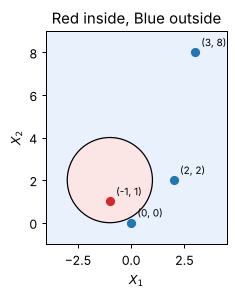

In [20]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(3.2, 3.4), dpi=90)
ax.set_facecolor("#e8f1fc")   # outside: Blue
ax.add_patch(Circle((-1, 2), 2, facecolor="#fce5e5", edgecolor="k"))   # inside: Red
for x1, x2 in [(0, 0), (-1, 1), (2, 2), (3, 8)]:
    red = (1 + x1) ** 2 + (2 - x2) ** 2 <= 4
    ax.scatter(x1, x2, color="tab:red" if red else "tab:blue", s=40, zorder=3)
    ax.annotate(f"({x1}, {x2})", (x1, x2), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set(xlim=(-4, 4.5), ylim=(-1, 9), aspect="equal", xlabel="$X_1$", ylabel="$X_2$",
       title="Red inside, Blue outside")
plt.tight_layout()
plt.show()